# Jordanian PC Builder — Phase 2 training notebook


## 1. Install dependencies


In [21]:
%pip -q install "transformers>=4.50,<5" "accelerate>=1,<2" "pymupdf>=1.24" "pandas>=2" "matplotlib>=3.7" "sentencepiece>=0.2"

## 2. Data & Configuration


###2.1 Calling the data

In [ ]:
!pip install gitpython -q

import git
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Read the token from the shared text file
# IMPORTANT: Update this path to exactly where the file is in your shared Drive
token_path = Path('/content/drive/MyDrive/Tokens/github-token.txt')
shared_token = token_path.read_text().strip()

# 3. Define the repository details and inject the token
repo_url = f"https://{shared_token}@github.com/Sulieman25/Jordanian-PC-Builder---DS493.git"
base_dir = Path("/content")
repo_name = "Jordanian-PC-Builder---DS493"
repo_path = base_dir / repo_name

# 4. Clone the repo
if not repo_path.exists():
    print(f"Cloning {repo_name}...")
    # GitPython requires string conversion for the destination path
    git.Repo.clone_from(repo_url, str(repo_path))
else:
    print(f"{repo_name} is already cloned.")

# 5. Assign paths to variables for your workflow using pathlib (/)
DATA_PATH = repo_path / "data"
CPT_DATA_PATH = DATA_PATH / "cpt"
SRC_PATH = repo_path / "src"
RESULTS_PATH = repo_path / "results"
TESTS_PATH = repo_path / "tests"
CSV_PATH = DATA_PATH / "components.csv"
TEST_CSV_PATH = TESTS_PATH / "test_questions.csv"
VERIFIED_QA_PATH = DATA_PATH / "sft_verified.jsonl"

# 6. Map the variables needed for the rest of the training notebook
OUTPUT_DIR = RESULTS_PATH

ARTICLE_DIR = DATA_PATH

USE_DRIVE = False # Switched to False because we are using the cloned GitHub repo now

# 7. Automatically discover all PDF articles
ARTICLE_PATHS = sorted(DATA_PATH.glob("*.pdf"))

# 8. Verify files
assert DATA_PATH.exists(), f"Folder not found: {DATA_PATH}"
assert CSV_PATH.exists(), f"CSV not found: {CSV_PATH}"

# 9. Print summaries
print("Repository cloned and paths assigned successfully.")
print(f"Components CSV: {CSV_PATH.name}")
print(f"Articles found: {len(ARTICLE_PATHS)}")

for article in ARTICLE_PATHS:
    print(article.name)

if len(ARTICLE_PATHS) != 15:
    print("Warning: Expected 15 PDF articles.")

In [ ]:
import ipywidgets as widgets
from IPython.display import display

# Define your team's details
teammates = {
    "Sulieman": "slymanwardat25@gmail.com",
    "Saif": "saif.pwned@gmail.com",
    "Yahya": "yahyaalqaryotey2005@gmail.com",
    "Shihab" :"shihabbattah6@gmail.com"
}

# Set default values
selected_name = list(teammates.keys())[0]
selected_email = teammates[selected_name]

# Create the dropdown menu
dropdown = widgets.Dropdown(
    options=list(teammates.keys()),
    description='Teammate:',
)

# Function to update variables when the dropdown changes
def on_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        global selected_name, selected_email
        selected_name = change['new']
        selected_email = teammates[selected_name]
        print(f"Commit author updated to: {selected_name} <{selected_email}>")

dropdown.observe(on_change)
display(dropdown)

###2.2 Configuration

In [23]:
#-----------[MODEL CONFIGURATION]-----------

MODEL_NAME = "gpt2"  # Alternative: "HuggingFaceTB/SmolLM2-135M"
SEED = 42

# CONTINUED PRETRAINING (CPT)
BLOCK_SIZE = 512
CATALOG_ROWS_PER_DOCUMENT = 60
CPT_EPOCHS = 2
CPT_LR = 5e-5

# SUPERVISED FINE-TUNING (SFT)
SFT_EPOCHS = 2
SFT_LR = 3e-5
SFT_MAX_LENGTH = 384
SFT_TARGET_CATALOG_PAIRS = 500

# TRAINING SETTINGS
TRAIN_BATCH_SIZE = 2
GRADIENT_ACCUMULATION = 4
EVAL_BATCH_SIZE = 2
MAX_TRAIN_STEPS = -1

# GENERATION SETTINGS
GEN_MAX_NEW_TOKENS = 75

# CONFIGURATION SUMMARY
print("Model:", MODEL_NAME)
print("CPT epochs:", CPT_EPOCHS)
print("SFT epochs:", SFT_EPOCHS)
print("Block size:", BLOCK_SIZE)

Model: gpt2
CPT epochs: 2
SFT epochs: 2
Block size: 512


## 3. Connect data and fix the random seed


In [24]:
#-----------[IMPORTS & ENVIRONMENT SETUP]-----------

import gc, json, math, random, re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from IPython.display import display
from transformers import set_seed

# Reproducibility
set_seed(SEED)

# GPU availability
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


##4. Cleaning, Loading & Converting Data

###4.1 Load and clean `components.csv`
Excluding rows with invalid prices from training.

In [25]:
#-----------[LOAD & CLEAN COMPONENTS]-----------

# Load catalogue
catalog = pd.read_csv(CSV_PATH)
original_count = len(catalog)

# Clean text columns
for col in ["store", "category", "product_name", "product_url"]:
    catalog[col] = catalog[col].fillna("").astype(str).str.strip()

# Convert prices to numeric
catalog["price_jod"] = pd.to_numeric(
    catalog["price_jod"], errors="coerce"
)

# Remove invalid products
catalog = catalog[
    (catalog["price_jod"] > 0) &
    (catalog["product_name"] != "") &
    (catalog["product_url"].str.startswith(("http://", "https://")))
]

# Remove duplicates, keeping the most recent listing
catalog = (
    catalog.sort_values("collected_at_utc")
    .drop_duplicates(subset="product_url", keep="last")
    .reset_index(drop=True)
)

# Summary
print("Original products:", original_count)
print("Usable products:", len(catalog))
print("Removed products:", original_count - len(catalog))

display(catalog["category"].value_counts())
display(catalog.head())


Original products: 2250
Usable products: 2245
Removed products: 5


,count
category,
GPU,445
Motherboard,408
Case,300
PSU,227
RAM,180
CPU,158
Liquid Cooling,147
SSD,144
Case Fan,77


,store,category,product_name,price_jod,product_url,collected_at_utc
0,Oriental Store,CPU,Intel Core Ultra 5 250KF Plus Processor (Serie...,259.0,https://os-jo.com/intel-core-ultra-5-250kf-plu...,2026-10-31T09:21:03+00:00
1,Oriental Store,CPU,AMD RYZEN 9 9900X Up to 5.6GHz 12 Cores 24 thr...,379.0,https://os-jo.com/amd-ryzen-9-9900x-up-to-5-6g...,2026-10-31T09:21:03+00:00
2,Oriental Store,CPU,AMD RYZEN 7 9700X Up to 5.5GHz 8 Cores 16 thre...,269.0,https://os-jo.com/amd-ryzen-7-9700x-up-to-5-5g...,2026-10-31T09:21:03+00:00
3,Oriental Store,CPU,AMD RYZEN 5 8400F Up to 4.7GHz 6 Cores 12 thre...,99.0,https://os-jo.com/amd-ryzen-5-8400f-up-to-4-7g...,2026-10-31T09:21:03+00:00
4,Oriental Store,CPU,AMD RYZEN 7 7700X Up To 5.4GHz 8 Cores 16 Thre...,219.0,https://os-jo.com/amd-ryzen-7-7700x-up-to-5-4g...,2026-10-31T09:21:03+00:00


###4.2 Extract *only* compatibility/article PDFs


In [26]:
#-----------[EXTRACT & CLEAN PDF ARTICLES]-----------

import pymupdf

#Clean extracted PDF text
def clean_pdf_text(text):

    #Remove invisible characters and website icons
    text = re.sub(r"[\x00\u00ad\uE000-\uF8FF]", " ", text)

    #Remove URLs and webpage timestamps
    text = re.sub(r"https?://\S+", " ", text)
    text = re.sub(
        r"(?m)^\s*\d{1,2}/\d{1,2}/\d{2,4},?\s+\d{1,2}:\d{2}\s*[AP]M",
        "", text
    )

    #Remove common website navigation
    text = re.sub(
        r"\b(?:SIGN IN|WISHLIST|CART|Cookie Policy|I agree|Only essentials)\b",
        " ", text, flags=re.IGNORECASE
    )

    #Remove common cookie notice
    text = re.sub(
        r"We use cookies to provide you a better user experience on this\s+website\.?",
        " ", text, flags=re.IGNORECASE
    )

    #Repair broken words and normalize whitespace
    text = re.sub(r"(?<=\w)-\n(?=\w)", "", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


#Extract PDF articles
article_docs = []

for path in ARTICLE_PATHS:
    with pymupdf.open(path) as pdf:
        text = "\n".join(
            page.get_text("text", sort=True)
            for page in pdf
        )

    text = clean_pdf_text(text)

    if len(text) < 400:
        print("Skipped (insufficient text):", path.name)
        continue

    article_docs.append({
        "kind": "article",
        "source": path.name,
        "text": text
    })


#Summary
print("PDFs found:", len(ARTICLE_PATHS))
print("Articles extracted:", len(article_docs))

for article in article_docs:
    print(article["source"], "-", len(article["text"]), "characters")

if article_docs:
    print("\nSample text:\n", article_docs[0]["text"][:500])


PDFs found: 14
Articles extracted: 14
Best Graphics Cards for Gaming in 2026 _ Tom's Hardware.pdf - 51912 characters
Best cheap gaming PC deals _ PC Gamer.pdf - 24737 characters
Best gaming PC builds_ Shop all our recommended system builds as we ride out the RAMpocalypse _ PC Gamer.pdf - 16915 characters
Best gaming PCs in 2026_ We've tested the best current-gen gaming PCs and these are our picks _ PC Gamer.pdf - 46209 characters
Buying PC Components_ Compatibility, Specs and Common Pitfalls.pdf - 9347 characters
Choose a Processor - OpenClassrooms.pdf - 13703 characters
Design Your Dream PC with CORSAIR _ CORSAIR.pdf - 13928 characters
How do I check if parts go together_ PC Compatibility Guide.pdf - 17746 characters
How to Build a PC (2025)_ Hardware Suggestions, Instructions, and More _ WIRED.pdf - 48604 characters
How to Choose a Motherboard and Compatible PC Parts Guide.pdf - 1063 characters
How to Choose a PC Case for Your Build_ Steps & Checklist.pdf - 11018 characters
How to Ch

###4.3 Convert real catalogue records into plain text


In [27]:
#-----------[CONVERT CATALOGUE TO TEXT]-----------

#Convert each product into readable text
def product_as_text(row):
    return (
        f"Category: {row['category']}\n"
        f"Product: {row['product_name']}\n"
        f"Store: {row['store']}\n"
        f"Price: {row['price_jod']:.2f} JOD"
    )


#Shuffle products reproducibly
products = catalog.to_dict("records")
random.Random(SEED).shuffle(products)

#Group products into training documents
catalog_docs = []

for i in range(0, len(products), CATALOG_ROWS_PER_DOCUMENT):
    batch = products[i:i + CATALOG_ROWS_PER_DOCUMENT]

    catalog_docs.append({
        "kind": "catalog",
        "source": f"catalog_batch_{i // CATALOG_ROWS_PER_DOCUMENT}",
        "text": "\n\n".join(product_as_text(row) for row in batch),
        "products": batch
    })


#Preview
print("Catalogue documents:", len(catalog_docs))
print("\nSample training text:\n")
print(catalog_docs[0]["text"][:600])

Catalogue documents: 38

Sample training text:

Category: Motherboard
Product: ASROCK X570 Phantom Gaming 4 ATX Motherboard
Store: Oriental Store
Price: 149.00 JOD

Category: SSD
Product: Kingston Dual Portable SSD (1TB) USB 3.2 Gen 2 (USB Type-A and Type-C) Portable External Solid State Drive (SSD) Up to Up to 1,050MB/s Read, 950MB/s Write
Store: Oriental Store
Price: 129.00 JOD

Category: Case
Product: Lian Li O11 Dynamic XL ROG Certified (Silver) Mid Tower Tempered Glass Gaming Case w/ ARGB Front Bar
Store: Oriental Store
Price: 169.00 JOD

Category: PSU
Product: Cooler Master V850 Gold V2 Full Modular Power Supply, 850W, 80+ Gold Effici


## 5. Document-level train/held-out split - 90/10 target
We split PDFs and catalogue batches **independently** so validation includes both source types. With very few PDFs, keeping one complete PDF held out may make the article fraction larger than 10%; that is better than splitting pages from one article between sets.

Products from held-out catalogue batches are **not** used to create SFT training examples.

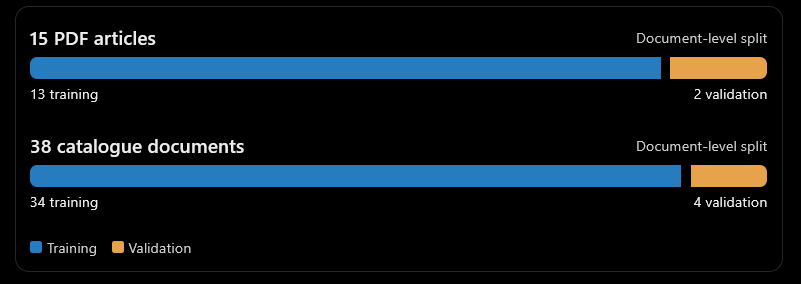

In [28]:
#-----------[TRAIN / VALIDATION SPLIT]-----------

#Split documents into 90% training and 10% validation
def split_documents(docs, seed):
    shuffled = docs.copy()
    random.Random(seed).shuffle(shuffled)

    n_val = max(1, round(len(shuffled) * 0.10))
    return shuffled[n_val:], shuffled[:n_val]


#Split articles and catalogue separately
train_article_docs, val_article_docs = split_documents(article_docs, SEED)
train_catalog_docs, val_catalog_docs = split_documents(catalog_docs, SEED + 1)

#Combine documents for CPT
train_docs = train_article_docs + train_catalog_docs
val_docs = val_article_docs + val_catalog_docs

#Extract product records for SFT
train_products = [
    product
    for doc in train_catalog_docs
    for product in doc["products"]
]

val_products = [
    product
    for doc in val_catalog_docs
    for product in doc["products"]
]

#Summary
print(f"Articles: {len(train_article_docs)} train / {len(val_article_docs)} validation")
print(f"Catalogue: {len(train_catalog_docs)} train / {len(val_catalog_docs)} validation")
print(f"Total: {len(train_docs)} train / {len(val_docs)} validation")
print(f"Products: {len(train_products)} train / {len(val_products)} validation")


Articles: 13 train / 1 validation
Catalogue: 34 train / 4 validation
Total: 47 train / 5 validation
Products: 2005 train / 240 validation


## 6. Load tokenizer and prepare fixed-length next-token sequences
Model choice is set in **one** configuration cell. We use the model's existing EOS as the padding token where a separate padding token is absent. Small incomplete remainders are not mixed between train and held-out sets.

###6.1 Tokenizer

In [29]:
#-----------[LOAD TOKENIZER & BASE MODEL]-----------

from transformers import AutoTokenizer, AutoModelForCausalLM

#Load tokenizer //Side note: AutoTokenizer has a wide variety of tokenizers it selects from if they're supported //Checks model name you're using -> Fetches it's tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

#Set padding token if missing //Side note: If a tokenizer has no padding token -> Use it's EOS Token instead
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

#Load pretrained model
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
base_model.config.pad_token_id = tokenizer.pad_token_id
base_model.to(DEVICE)

#Summary
print("Model:", MODEL_NAME)
print("Parameters:", f"{sum(p.numel() for p in base_model.parameters()):,}")


Model: gpt2
Parameters: 124,439,808


###6.2 Packing Documents for Continued Pretraining (CPT)

Take PC-Building Documents and turn them into training examples that the model can learn from.



1. Convert documents into token sequences.

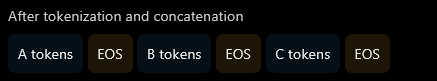


2.   Package those sequences into a PyTorch dataset.

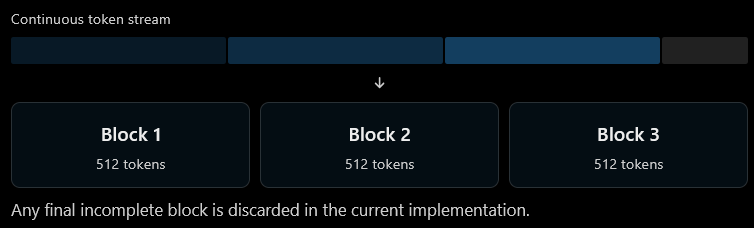



3. Create separate training and validation datasets.



In [30]:
#-----------[PACK DOCUMENTS FOR CPT]-----------

from torch.utils.data import Dataset

#Convert documents into token blocks
def pack_documents(documents, tokenizer, block_size):
    tokens = []

    for doc in documents:
        tokens.extend(
            tokenizer.encode(doc["text"], add_special_tokens=False)
        )
        tokens.append(tokenizer.eos_token_id)

    blocks = [
        tokens[i:i + block_size]
        for i in range(0, len(tokens) - block_size + 1, block_size)
    ]

    return blocks, len(tokens)


#PyTorch dataset for causal language modeling (Make the sequence usable by PyTorch)
class CPTDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks

    def __len__(self):
        return len(self.blocks)

    def __getitem__(self, idx):
        tokens = torch.tensor(self.blocks[idx], dtype=torch.long)

        return {
            "input_ids": tokens,
            "attention_mask": torch.ones_like(tokens),
            "labels": tokens.clone()
        }


#Tokenize training and validation documents separately
train_blocks, train_token_count = pack_documents(
    train_docs, tokenizer, BLOCK_SIZE
)

heldout_blocks, heldout_token_count = pack_documents(
    val_docs, tokenizer, BLOCK_SIZE
)

#Create datasets
cpt_train_ds = CPTDataset(train_blocks)
cpt_val_ds = CPTDataset(heldout_blocks)

#Summary
print("Training tokens:", train_token_count)
print("Validation tokens:", heldout_token_count)
print("Training sequences:", len(cpt_train_ds))
print("Validation sequences:", len(cpt_val_ds))


Token indices sequence length is longer than the specified maximum sequence length for this model (9675 > 1024). Running this sequence through the model will result in indexing errors


Training tokens: 176091
Validation tokens: 24656
Training sequences: 343
Validation sequences: 48


E.g.: `cpt_train_ds[0]` should return the first 512-token training example



> `input_ids`	The actual token IDs the model reads

>`attention_mask`	Tells the model which positions contain valid tokens

>`labels`	The correct tokens used to compute the training loss



## 7. Base-model checkpoint & Evaluation


Baseline experiment before it learns anything from our data.

It performs two evaluations:
1. Perplexity: How well can the model predict text from our held-out `PCBuilding Data`.
2. Text generation: What does the model produce when given five `PCBuilding` prompts?


In [31]:
#-----------[BASE MODEL EVALUATION]-----------

from torch.utils.data import DataLoader


#Calculate loss and perplexity on held-out data
@torch.no_grad() #Don't calculate gradients, we're not updating model weights (training)
def evaluate_cpt_perplexity(model, dataset):
    model.eval()

    loader = DataLoader(dataset, batch_size=EVAL_BATCH_SIZE) #Config param: divide into batches (e.g. 2, evaluate two blocks at a time)

    total_loss = 0
    total_tokens = 0

    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}

        loss = model(**batch).loss.item()
        n_tokens = (batch["labels"][:, 1:] != -100).sum().item()

        total_loss += loss * n_tokens
        total_tokens += n_tokens

    avg_loss = total_loss / total_tokens

    return {
        "loss": avg_loss,
        "perplexity": math.exp(avg_loss) # e^(averageLoss)
    }


#Generate text using greedy decoding
@torch.no_grad()
def complete_prompt(model, tok, prompt, max_new_tokens=GEN_MAX_NEW_TOKENS):
    model.eval()

    inputs = tok(prompt, return_tensors="pt").to(DEVICE)

    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        eos_token_id=tok.eos_token_id,
        pad_token_id=tok.pad_token_id
    )

    generated = outputs[0, inputs["input_ids"].shape[1]:]

    return tok.decode(generated, skip_special_tokens=True).strip()


#Fixed prompts for comparison before and after CPT
CONTINUATION_PROMPTS = [
    "CPU and motherboard compatibility depends on",
    "DDR4 and DDR5 memory are different because",
    "When choosing a power supply for a gaming PC,",
    "A PC case must support the motherboard",
    "Before assembling a computer, it is important to"
]


#Evaluate base model
base_metrics = evaluate_cpt_perplexity(base_model, cpt_val_ds)

print("Base loss:", round(base_metrics["loss"], 4))
print("Base perplexity:", round(base_metrics["perplexity"], 4))


#Generate baseline completions
base_continuations = [
    complete_prompt(base_model, tokenizer, prompt)
    for prompt in CONTINUATION_PROMPTS
]


#Display and save results
baseline_results = pd.DataFrame({
    "Prompt": CONTINUATION_PROMPTS,
    "Base Response": base_continuations
})

display(baseline_results)

baseline_results.to_csv(
    OUTPUT_DIR / "base_continuations.csv",
    index=False
)


Base loss: 3.9329
Base perplexity: 51.0544


,Prompt,Base Response
0,CPU and motherboard compatibility depends on,the motherboard.\n\nThe following table lists ...
1,DDR4 and DDR5 memory are different because,they are different in that they are different ...
2,"When choosing a power supply for a gaming PC,",you should consider the following factors:\n\n...
3,A PC case must support the motherboard,"'s operating system, and the motherboard must ..."
4,"Before assembling a computer, it is important to",understand the basic concepts of the computer....


## 8. Continued Pretraining (CPT) - next-token prediction


`Actual training starts here` -> Train model on our PC-Building Data

In [32]:

#-----------[CONTINUED PRETRAINING]-----------

from transformers import Trainer, TrainingArguments, EarlyStoppingCallback

#Select GPU precision <Conserves memory for Colab GPUs>
AMP_BF16 = DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()
AMP_FP16 = DEVICE.type == "cuda" and not AMP_BF16

#Training configuration
cpt_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "cpt_checkpoints"),

    #Hyperparameters
    num_train_epochs=CPT_EPOCHS, #Passes over training data
    max_steps=MAX_TRAIN_STEPS,
    learning_rate=CPT_LR, #Controls size of weight updates
    per_device_train_batch_size=TRAIN_BATCH_SIZE, #Process this many sequences per batch
    per_device_eval_batch_size=EVAL_BATCH_SIZE, #Evaluate this many sequences at a time
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,

    #Logging, evaluation and checkpoints
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=3,

    #Select best checkpoint
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",

    #GPU precision
    bf16=AMP_BF16,
    fp16=AMP_FP16,

    seed=SEED,
    report_to="none"
)

#Disable caching during training //Side note: Causal language models can cache previously computed attention key/value states to make autoregressive text generation faster. This cache is useful during generation, but unnecessary for this full-sequence training workflow.
base_model.config.use_cache = False

#Initialize trainer
cpt_trainer = Trainer(
    model=base_model, #Chosen baseline model with its original pretrained weights
    args=cpt_args,
    train_dataset=cpt_train_ds,
    eval_dataset=cpt_val_ds,
    processing_class=tokenizer, #To convert between text and token IDs
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

# Train the model
cpt_trainer.train()

#Restore caching
base_model.config.use_cache = True

#Save trained model
CPT_MODEL_PATH = OUTPUT_DIR / "cpt_model"
cpt_trainer.save_model(str(CPT_MODEL_PATH))

#Save training history
cpt_history = cpt_trainer.state.log_history

with open(OUTPUT_DIR / "cpt_history.json", "w") as f:
    json.dump(cpt_history, f, indent=2)

print("CPT completed.")
print("Model saved to:", CPT_MODEL_PATH)


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 50256}.


Epoch,Training Loss,Validation Loss
1,2.686500,2.703489
2,2.405000,2.617188


There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


CPT completed.
Model saved to: /content/drive/MyDrive/Special Topics - Data/notebook_outputs/cpt_model


Both training and validation loss decreased which is a good indicator that no Overfitting happened.

## 9. Inspect CPT results and compare the original five prompts

Base perplexity: 51.054
CPT perplexity: 13.767


,Prompt,Base Model,After CPT
0,CPU and motherboard compatibility depends on,the motherboard.\n\nThe following table lists ...,your system.\n\nIf you have a motherboard that...
1,DDR4 and DDR5 memory are different because,they are different in that they are different ...,they are not interchangeable.\n\nThe DDR5 memo...
2,"When choosing a power supply for a gaming PC,",you should consider the following factors:\n\n...,it's important to know the type of power suppl...
3,A PC case must support the motherboard,"'s operating system, and the motherboard must ...",", motherboard, and USB 3.2 Gen2 Type-C ports.\..."
4,"Before assembling a computer, it is important to",understand the basic concepts of the computer....,know how to build a system.\n\nThe first step ...


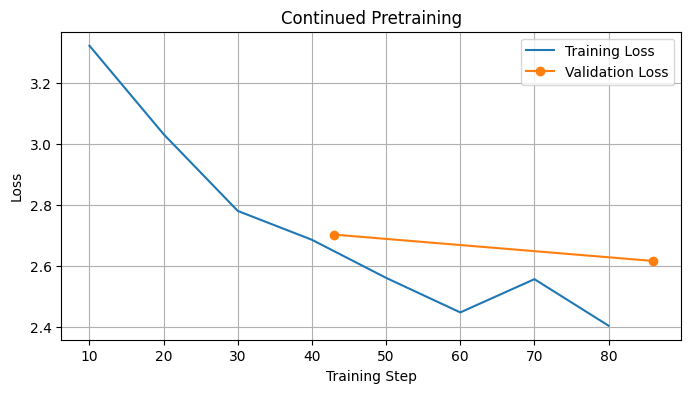

In [33]:
#-----------[EVALUATE CPT RESULTS]-----------

#Evaluate perplexity after CPT
cpt_metrics = evaluate_cpt_perplexity(base_model, cpt_val_ds)

print("Base perplexity:", round(base_metrics["perplexity"], 3))
print("CPT perplexity:", round(cpt_metrics["perplexity"], 3))


#Compare responses before and after CPT
cpt_continuations = [
    complete_prompt(base_model, tokenizer, prompt)
    for prompt in CONTINUATION_PROMPTS
]

comparison = pd.DataFrame({
    "Prompt": CONTINUATION_PROMPTS,
    "Base Model": base_continuations,
    "After CPT": cpt_continuations
})

display(comparison)
comparison.to_csv(OUTPUT_DIR / "cpt_comparison.csv", index=False)


#Plot training and validation loss
history = pd.DataFrame(cpt_history)

train_history = history.dropna(subset=["loss"])
val_history = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(8, 4))

plt.plot(
    train_history["step"],
    train_history["loss"],
    label="Training Loss"
)

plt.plot(
    val_history["step"],
    val_history["eval_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Continued Pretraining")
plt.legend()
plt.grid(True)

plt.savefig(OUTPUT_DIR / "cpt_loss.png", dpi=150, bbox_inches="tight")
plt.show()


In [34]:
comparison

,Prompt,Base Model,After CPT
0,CPU and motherboard compatibility depends on,the motherboard.\n\nThe following table lists ...,your system.\n\nIf you have a motherboard that...
1,DDR4 and DDR5 memory are different because,they are different in that they are different ...,they are not interchangeable.\n\nThe DDR5 memo...
2,"When choosing a power supply for a gaming PC,",you should consider the following factors:\n\n...,it's important to know the type of power suppl...
3,A PC case must support the motherboard,"'s operating system, and the motherboard must ...",", motherboard, and USB 3.2 Gen2 Type-C ports.\..."
4,"Before assembling a computer, it is important to",understand the basic concepts of the computer....,know how to build a system.\n\nThe first step ...


## 10. Prepare SFT Q&A pairs (source-backed, not invented)


In [ ]:
#-----------[LOAD & SPLIT SFT DATASET]-----------

# Load all 500 question-answer pairs
SFT_PATH = DATA_PATH / "sft_pairs.jsonl"

with open(SFT_PATH, encoding="utf-8") as f:
    sft_pairs = [json.loads(line) for line in f if line.strip()]


# Split into 90% training and 10% validation
# Keep related Arabic/English questions together
groups = sorted({pair["group_id"] for pair in sft_pairs})
random.Random(SEED).shuffle(groups)

val_groups = set(groups[:round(len(groups) * 0.10)])

sft_train_pairs = [
    pair for pair in sft_pairs
    if pair["group_id"] not in val_groups
]

sft_val_pairs = [
    pair for pair in sft_pairs
    if pair["group_id"] in val_groups
]


# Summary
print("Total SFT pairs:", len(sft_pairs))
print("Training pairs:", len(sft_train_pairs))
print("Validation pairs:", len(sft_val_pairs))

display(pd.DataFrame(sft_train_pairs)[["question", "answer", "type"]].head())


Total SFT pairs: 500
Training pairs: 448
Validation pairs: 52


,question,answer,type
0,What are the three broad kinds of component in...,"Technological, electrical, and physical mismat...",technical_article
1,ما الأنواع الرئيسية لمشكلات توافق قطع الكمبيوتر؟,التعارض قد يكون تقنياً أو كهربائياً أو متعلقاً...,technical_article
2,What must match between a CPU and motherboard ...,The CPU socket must match the motherboard sock...,technical_article
3,شو أول شي أتأكد منه بين المعالج والمذربورد؟,تطابق المقبس، ثم دعم اللوحة لطراز المعالج وجيله.,technical_article
4,Which socket is used by mainstream desktop Ryz...,Ryzen 7000 desktop processors use AM5; verify ...,technical_article




--------------------------------------------

>----------------------SAIF VERSION ENDS HERE----------------------


>Everything up to Preparing and Splitting the SFT Q&A pairs is done.

>All previous cells have been rewritten and optimized perfectly. Do not touch.

>Comments have been added.

>Text cells have been reformatted and Sections have been reorganized, follow it.
--------------------------------------------

## 13. Inspect Q&A candidates and split SFT pairs 90/10
For course submission, inspect and verify generated examples (at least 50 if LLM-generated; manual checking is still recommended for these templated examples), add some compatibility Q&As, and ensure the official 30 test questions are absent. This notebook does not fabricate approvals.

In [ ]:
rng = random.Random(SEED + 3)
sft_shuffled = sft_pairs.copy(); rng.shuffle(sft_shuffled)
val_n = max(1, round(len(sft_shuffled) * 0.1))
sft_val_pairs = sft_shuffled[:val_n]
sft_train_pairs = sft_shuffled[val_n:]
assert set(normalize_question(x["question"]) for x in sft_train_pairs).isdisjoint(
       normalize_question(x["question"]) for x in sft_val_pairs)
write_jsonl(OUTPUT_DIR / "sft_train.jsonl", sft_train_pairs)
write_jsonl(OUTPUT_DIR / "sft_val.jsonl", sft_val_pairs)
print("SFT:", len(sft_train_pairs), "train;", len(sft_val_pairs), "validation")
print("Check samples before training:")
for p in sft_train_pairs[:5]:
    print("Q:", p["question"][:180], "\nA:", p["answer"][:200], "\n")

## 14. Define model-independent SFT chat format with **answer-only** loss
GPT-2 does not have a standard chat format. To support both GPT-2 and other causal LMs consistently, we add three explicit markers and mask question/prompt tokens with `-100` in the training labels. **Only the answer and end marker contribute to SFT loss**.

This is deliberately implemented with `Trainer` rather than version-sensitive SFT trainer options.

In [ ]:
CHAT_MARKERS = ["<|user|>", "<|assistant|>", "<|end|>"]
tokenizer.add_special_tokens({"additional_special_tokens": CHAT_MARKERS})
base_model.resize_token_embeddings(len(tokenizer))
base_model.config.pad_token_id = tokenizer.pad_token_id

def encode_sft_pair(pair, tok, max_len):
    prompt = f"<|user|>\n{pair['question']}\n<|assistant|>\n"
    answer = f"{pair['answer']}<|end|>"
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    a_ids = tok(answer, add_special_tokens=False)["input_ids"]
    # Never truncate an answer invisibly: drop too-long examples and review separately.
    if not a_ids or len(p_ids) + len(a_ids) > max_len:
        return None
    return {"input_ids":p_ids+a_ids,
            "attention_mask":[1]*(len(p_ids)+len(a_ids)),
            "labels":[-100]*len(p_ids)+a_ids}

class SFTDataset(Dataset):
    def __init__(self, pairs, tok, max_len):
        self.samples = [x for p in pairs if (x:=encode_sft_pair(p,tok,max_len)) is not None]
    def __len__(self): return len(self.samples)
    def __getitem__(self, i): return self.samples[i]

class SFTCollator:
    def __init__(self, pad_id): self.pad_id = pad_id
    def __call__(self, features):
        length = max(len(x["input_ids"]) for x in features)
        result = {"input_ids":[], "attention_mask":[], "labels":[]}
        for x in features:
            n = length - len(x["input_ids"])
            result["input_ids"].append(x["input_ids"]+[self.pad_id]*n)
            result["attention_mask"].append(x["attention_mask"]+[0]*n)
            result["labels"].append(x["labels"]+[-100]*n)
        return {k:torch.tensor(v,dtype=torch.long) for k,v in result.items()}

sft_train_ds = SFTDataset(sft_train_pairs, tokenizer, SFT_MAX_LENGTH)
sft_val_ds = SFTDataset(sft_val_pairs, tokenizer, SFT_MAX_LENGTH)
print("Tokenized SFT:", len(sft_train_ds), "train /", len(sft_val_ds), "validation")
assert len(sft_train_ds) > 0 and len(sft_val_ds) > 0, "SFT samples exceed SFT_MAX_LENGTH; increase it."
example = sft_train_ds[0]
first_answer = next(i for i, label in enumerate(example["labels"]) if label != -100)
assert all(x == -100 for x in example["labels"][:first_answer])
assert all(x != -100 for x in example["labels"][first_answer:])
print("Masked question tokens:", first_answer, "| supervised answer tokens:", len(example["labels"])-first_answer)
print("First answer preview:", tokenizer.decode(example["input_ids"][first_answer:first_answer+50], skip_special_tokens=True))

## 15. Supervised fine-tuning (SFT)
Starts from the model just continued-pretrained, not from a fresh base model. Saves independent checkpoints and an SFT final model. Change **MODEL_NAME** at the top to switch models; no GPT-2-specific code is used.

In [ ]:
sft_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "sft_checkpoints"),
    num_train_epochs=SFT_EPOCHS,
    max_steps=MAX_TRAIN_STEPS,
    learning_rate=SFT_LR,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,
    logging_strategy="steps", logging_steps=10,
    eval_strategy="epoch", save_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
    save_total_limit=3, report_to="none", seed=SEED,
    bf16=AMP_BF16, fp16=AMP_FP16, optim="adamw_torch"
)
base_model.config.use_cache = False
sft_trainer = Trainer(
    model=base_model, args=sft_args,
    train_dataset=sft_train_ds, eval_dataset=sft_val_ds,
    data_collator=SFTCollator(tokenizer.pad_token_id),
    processing_class=tokenizer,
)
sft_trainer.train()
sft_trainer.save_model(str(OUTPUT_DIR / "sft_model"))
tokenizer.save_pretrained(str(OUTPUT_DIR / "sft_model"))
sft_history = sft_trainer.state.log_history
(OUTPUT_DIR / "sft_history.json").write_text(json.dumps(sft_history, indent=2),encoding="utf-8")
base_model.config.use_cache = True
print("SFT model saved:", OUTPUT_DIR / "sft_model")

## 16. Inspect SFT loss curve

In [ ]:
hist = pd.DataFrame(sft_history)
fig, ax = plt.subplots(figsize=(8, 4))
for key, label in [("loss", "Train loss"), ("eval_loss", "Validation loss")]:
    if key in hist:
        p = hist.dropna(subset=[key]); ax.plot(p["step"], p[key], marker="o", label=label)
ax.set(xlabel="Training step", ylabel="Answer-only loss", title="SFT training")
ax.legend(); plt.show()

## 17. Compare **five test questions** across base, CPT and SFT
Use the **same semantic questions** and greedy decoding for all three models. The SFT version needs its trained chat tags; the base and CPT models use a plain `Question: … Answer:` prompt. The two price examples come from **held-out catalogue records**, so their prices are source references for you, not facts these models are expected to memorize.

If you provide the Phase 1 `test_questions.csv`, the first five actual test questions are used instead of the built-in smoke tests. This section **shows examples only**; it is not the full 30-question scored evaluation required for submission.

In [ ]:
if official_test is not None and len(official_test):
    prompt_questions = official_test["question"].astype(str).head(5).tolist()
    expected_answers = official_test.get("expected_answer", pd.Series([""]*len(official_test))).astype(str).head(5).tolist()
    print("Using first five official Phase 1 questions")
else:
    heldout_examples = val_products[:2]
    price_qs = [f"At {r['store']}, what is the listed price in JOD of {r['product_name']}?"
                for r in heldout_examples]
    expected_price = [f"{float(r['price_jod']):.2f} JOD (snapshot {str(r['collected_at_utc'])[:10]})"
                      for r in heldout_examples]
    prompt_questions = DEMO_COMPATIBILITY_QUESTIONS + price_qs
    expected_answers = ["Requires verification from actual compatibility articles and component specs"]*3 + expected_price
    print("No official test CSV: using five DEMO prompts, not official evaluation")
assert len(prompt_questions) == 5

# Free CUDA memory before loading each model sequentially.
del sft_trainer, cpt_trainer, base_model
gc.collect(); torch.cuda.empty_cache()

@torch.no_grad()
def predict_from_checkpoint(model_location, questions, use_chat=False):
    tok = AutoTokenizer.from_pretrained(model_location, use_fast=True)
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(model_location).to(DEVICE)
    model.config.pad_token_id = tok.pad_token_id
    predictions = [complete_prompt(model, tok, q if use_chat else f"Question: {q}\nAnswer:", chat=use_chat)
                   for q in questions]
    del model
    gc.collect(); torch.cuda.empty_cache()
    return predictions

base_answers = predict_from_checkpoint(MODEL_NAME, prompt_questions)
cpt_answers = predict_from_checkpoint(str(OUTPUT_DIR / "cpt_model"), prompt_questions)
sft_answers = predict_from_checkpoint(str(OUTPUT_DIR / "sft_model"), prompt_questions, use_chat=True)

comparison = pd.DataFrame({
    "question": prompt_questions,
    "reference_or_note": expected_answers,
    "base": base_answers,
    "after_CPT": cpt_answers,
    "after_SFT": sft_answers,
})
display(comparison)
comparison.to_csv(OUTPUT_DIR / "five_prompt_comparison.csv", index=False)
print("Saved:", OUTPUT_DIR / "five_prompt_comparison.csv")

## 18. Save a compact experiment record and stop
This is the end of the notebook. The complete Phase 2 scoreboard, independent grading of 30 questions, refusal accuracy, error analysis, and the final build-compatibility optimizer are **separate later steps** — not falsely presented as finished here.

In [ ]:
run_summary = {
    "model": MODEL_NAME, "seed":SEED, "block_size":BLOCK_SIZE,
    "catalogue_raw_rows":int(len(raw_catalog)),
    "catalogue_usable_rows":int(len(catalog)),
    "article_count":len(article_docs),
    "cpt_train_documents":len(train_docs), "cpt_heldout_documents":len(val_docs),
    "cpt_train_tokens":train_token_count, "cpt_heldout_tokens":heldout_token_count,
    "base_heldout_perplexity":base_metrics["perplexity"],
    "cpt_heldout_perplexity":cpt_metrics["perplexity"],
    "sft_train_pairs":len(sft_train_ds), "sft_val_pairs":len(sft_val_ds),
    "official_test_csv_supplied":official_test is not None,
    "artifacts": ["cpt_model/", "sft_model/", "five_prompt_comparison.csv", "cpt_history.json", "sft_history.json"]
}
(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(run_summary,indent=2), encoding="utf-8")
display(pd.Series(run_summary, name="value").to_frame())
print("Done. Everything is in:", OUTPUT_DIR)

In [ ]:
if upload_decision:
    print("Starting upload sequence...")

    !pip install huggingface_hub -q

    from huggingface_hub import HfApi

    hf_token_path = '/content/drive/MyDrive/Tokens/hf-token.txt'

    with open(hf_token_path, 'r') as file:
        shared_hf_token = file.read().strip()

    # 2. Initialize the Hugging Face API
    api = HfApi()

    # 3. Inject the author's name
    hf_commit_message = f"Update GPT-2 checkpoints. Uploaded by: {selected_name}"

    print(f"Uploading model weights to Hugging Face as {selected_name}...")

    # 4. Push the folder to your private Organization repository
    try:
        api.upload_folder(
            folder_path=RESULTS_PATH,
            repo_id="ds493-pc-builder/pc-builder", # Organization-Name/Model-Name
            repo_type="model",
            token=shared_hf_token,
            commit_message=hf_commit_message,
            allow_patterns=["*.safetensors", "*.bin", "*.json", "tokenizer*"]
        )
        print("Upload to Hugging Face complete!")
    except Exception as e:
        print(f"\nFailed to push to Hugging Face. Error: {e}")

    # [Paste the GitHub git.Repo code here]
    repo = git.Repo(repo_path)
    origin = repo.remotes.origin

    print("Pulling latest changes from GitHub...")
    origin.pull(rebase=True)

    print("Staging all modified and new files...")
    repo.git.add(all=True)

    if repo.is_dirty(untracked_files=True):
        # Pauses to ask for a commit message
        commit_message = input("Enter a commit message: ") or "Update RAG system files from Colab"

        # Apply the author variables chosen in Cell 2
        repo.config_writer().set_value("user", "name", selected_name).release()
        repo.config_writer().set_value("user", "email", selected_email).release()

        repo.index.commit(commit_message)
        print("Commit successful. Pushing to GitHub...")

        try:
            origin.push()
            print("Upload complete!")
        except Exception as e:
            print(f"\nFailed to push. Error: {e}")
    else:
        print("No new changes detected. Skipping commit and push.")

else:
    print("Local run complete. Upload skipped based on dropdown selection.")